Je teste

In [5]:
%pip install torch-geometric

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import torch
from torch_geometric.nn import GCNConv
from torch_geometric.datasets import KarateClub
from torch_geometric.data import Data

dataset = KarateClub()
data = dataset[0]

from torch_geometric.datasets import Planetoid

dataset2 = Planetoid(root="/tmp/Cora", name="Cora")
data2 = dataset2[0]

print(f"Number of nodes: {data2.num_nodes}")  # 2708
print(f"Number of edges: {data2.num_edges}")  # 10556
print(f"Node feature dim: {data2.num_node_features}")  # 1433
print(f"Number of classes: {dataset2.num_classes}")  # 7
print(f"Train mask count: {data2.train_mask.sum().item()}")  # 140

print(f"Number of nodes: {data.num_nodes}")  # 34
print(f"Number of edges: {data.num_edges}")  # 156 (directed representation)
print(f"Node feature dim: {data.num_node_features}")  # 34 (identity matrix)
print(f"Number of classes: {dataset.num_classes}")  # 4
print(f"Edge index shape: {data.edge_index.shape}")  # [2, 156]

print(data)

class GCN(torch.nn.Module):

  def __init__(self):
    super().__init__()
    self.conv1 = GCNConv(dataset.num_features, 16)
    self.conv2 = GCNConv(16, dataset.num_classes)

  def forward(self, x, edge_index):
    x = self.conv1(x, edge_index).relu()
    return self.conv2(x, edge_index)

Number of nodes: 2708
Number of edges: 10556
Node feature dim: 1433
Number of classes: 7
Train mask count: 140
Number of nodes: 34
Number of edges: 156
Node feature dim: 34
Number of classes: 4
Edge index shape: torch.Size([2, 156])
Data(x=[34, 34], edge_index=[2, 156], y=[34], train_mask=[34])


Data(x=[34, 34], edge_index=[2, 156])


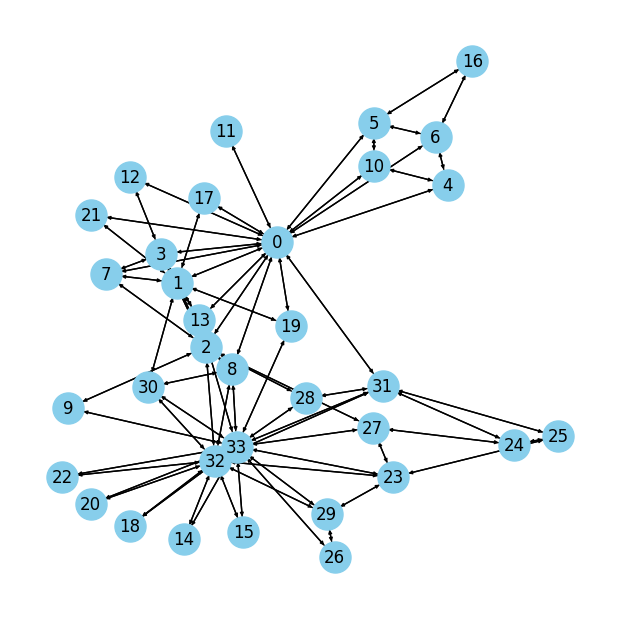

In [10]:
graph = Data(x=data.x, edge_index=data.edge_index)
print(graph)

import matplotlib.pyplot as plt
import networkx as nx
from torch_geometric.utils import to_networkx

G = to_networkx(graph, to_undirected=False)

plt.figure(figsize=(6, 6))
pos = nx.spring_layout(G, seed=42)
nx.draw(G,pos,with_labels=True,node_color="skyblue",node_size=500,arrowsize=5)
